# 電極周囲を含む計算領域と格子

Pythonの `SimulationConfig` と `initialize_grid()` を使います。
計算条件は設定セルのConfigに集約し、Juliaの設定ファイルは参照しません。
電極先端の高さ `electrode_gap` は、領域上端 `nz*delta` から独立しています。
左は双曲線電極と領域、右は実際の気体・電極セルの階段状近似です。
このNotebookではPoisson求解や時間発展は行いません。


In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

project = next((p for base in (Path.cwd(), *Path.cwd().parents)
                for p in (base, base/'streamer_python')
                if (p/'streamer_drift_diffusion').is_dir()), None)
if project is None:
    raise FileNotFoundError('streamer_python またはその親フォルダから実行してください')
sys.path.insert(0, str(project))
from streamer_drift_diffusion import SimulationConfig
from streamer_drift_diffusion.grid import initialize_grid

config = SimulationConfig()
grid = initialize_grid(config)
r_edges = np.arange(config.nr+1)*config.delta*1e3
z_edges = np.arange(config.nz+1)*config.delta*1e3
radius, height = r_edges[-1], z_edges[-1]
print(f'Grid: {config.nr} x {config.nz}, spacing {config.delta*1e6:g} um')
print(f'Domain: {radius:g} x {height:g} mm; tip: {config.electrode_gap*1e3:g} mm')


Grid: 200 x 150, spacing 10 um
Domain: 2 x 1.5 mm; tip: 1 mm


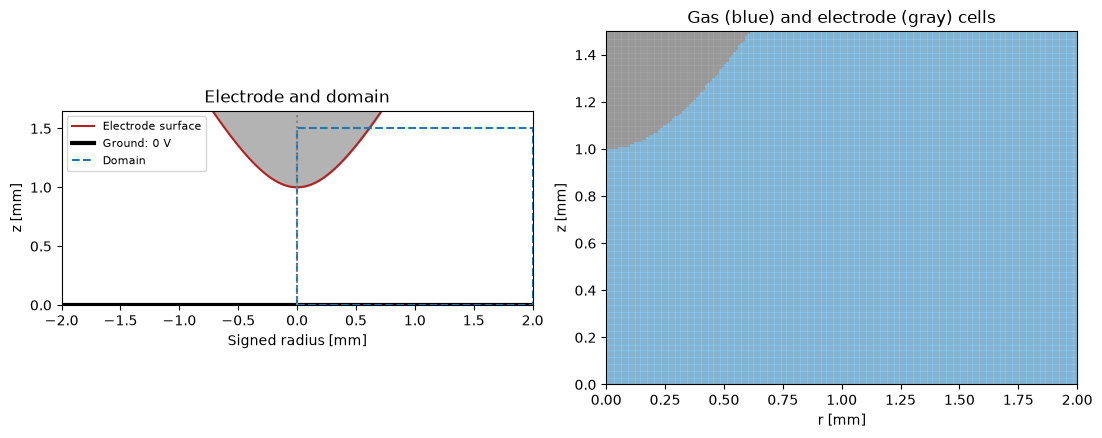

In [2]:
fig, (ax, mesh) = plt.subplots(1, 2, figsize=(11, 5), layout='constrained')
r = np.linspace(-radius, radius, 600)
b = config.electrode_gap
surface = b*np.sqrt(1+(r*1e-3)**2/(config.cathode_radius*b))*1e3
top = height*1.1
ax.fill_between(r, surface, top, where=surface<top, color='0.7')
ax.plot(r, surface, color='firebrick', label='Electrode surface')
ax.axhline(0, color='black', lw=3, label='Ground: 0 V')
ax.plot([0, radius, radius, 0, 0], [0, 0, height, height, 0], '--', label='Domain')
ax.axvline(0, color='0.5', ls=':')
ax.set(xlim=(-radius, radius), ylim=(0, top), xlabel='Signed radius [mm]',
       ylabel='z [mm]', title='Electrode and domain')
ax.legend(fontsize=8)
mesh.pcolormesh(r_edges, z_edges, grid['gas_mask'].T,
                cmap=ListedColormap(['0.65', 'lightskyblue']), shading='flat')
mesh.vlines(r_edges, 0, height, color='0.5', lw=.25)
mesh.hlines(z_edges, 0, radius, color='0.5', lw=.25)
mesh.set(xlim=(0, radius), ylim=(0, height), xlabel='r [mm]', ylabel='z [mm]',
         title='Gas (blue) and electrode (gray) cells')
for axis in (ax, mesh):
    axis.set_aspect('equal')
plt.show()
